In [1]:
import numpy as np
import csv
import matplotlib.pyplot as plt

# Overview
This program provides functions that can be used to calculate Joint and Marginal spectrums using time of flight spectroscopy. Since this won't be calibrated to properly correspond to frequency or wavelength, I refer to these as 'temporal' intensities rather than spectral

## Expectations
This program was written assuming the data provided is from the ID900/ID1000 software and that the "include start index" option was selected. It also assumes that coincidences only occur within the same 'pulse' as defined by the start channel on the timetaggers. It also has some default values for the temporal delays for time of flight spectroscopy. These delays were those that were relevant for my experiment but may not be appropriate for yours, so make sure to adjust the values accordingly.

### Todo
- Include proper example files in the repo and update this to work with the example files
- Move the actual functionality to its own python file, and include that file here, rather than writing the code to do analysis here

In [2]:
# Marginal Spectrum
def marginal_temporal_intensity(file, temporal_max = 10000, step = 100):
    with open(file, newline='') as csvfile:
        datareader = csv.reader(csvfile, delimiter=';')
        data = list(map(lambda x: int(x[0]),datareader))
        bins = int(np.ceil(temporal_max/step))
        plt.hist(data, histtype='step', bins=bins,range=(0,temporal_max))

This helper function is used to find the matching pulse assuming that coincidences only occur relative to the same refrence signal (the start signal on the ID900/ID1000 software)

In [3]:
def index_sorted(data,value,start):
    index = start
    length = len(data)
    while(index < length and data[index] <= value):
        if (data[index] == value):
            return index
        index = index+1
    return -1

In [4]:
def joint_temporal_intensity(file1,file2,extent = (2000,6000,2000,6000), gridsize = 40):
     with open(file1, newline='') as csvfile1:
         datareader1 = csv.reader(csvfile1,delimiter=';')
         data1 = list(map(lambda x: [int(x[0]),int(x[1])],datareader1))
         with open(file2, newline='') as csvfile2:
             datareader2 = csv.reader(csvfile2,delimiter=';')
             data2 = list(map(lambda x: [int(x[0]),int(x[1])],datareader2))
             times2 = list(map(lambda x: x[0],data2))
             pulses2 = list(map(lambda x: x[1], data2))
             joint_x = []
             joint_y = []
             start = 0
             for datum in data1:
                 pulse = datum[1]
                 index = index_sorted(pulses2, pulse,start)
                 if index == -1:
                     continue
                 start = index
                 joint_x.append(datum[0])
                 joint_y.append(times2[index])
             #print(joint_values)
             fig, ax = plt.subplots()
             hb = ax.hexbin(joint_x,joint_y, gridsize = gridsize, extent = extent,cmap = 'inferno')
             fig.colorbar(hb, ax=ax, label='counts')

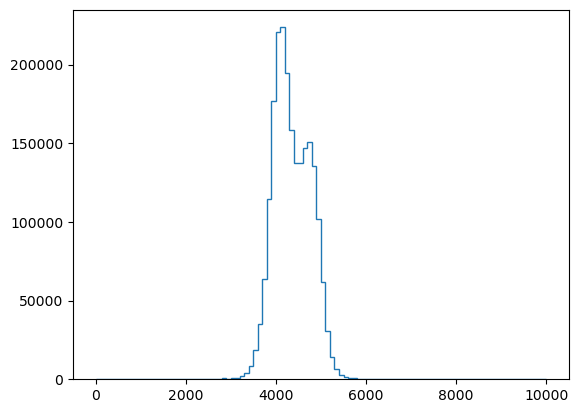

In [5]:
marginal_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_357K_1p3muW_C1.txt")

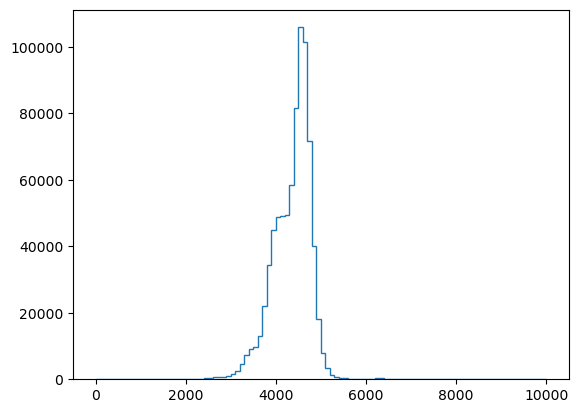

In [6]:
marginal_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_357K_1p3muW_C2.txt")

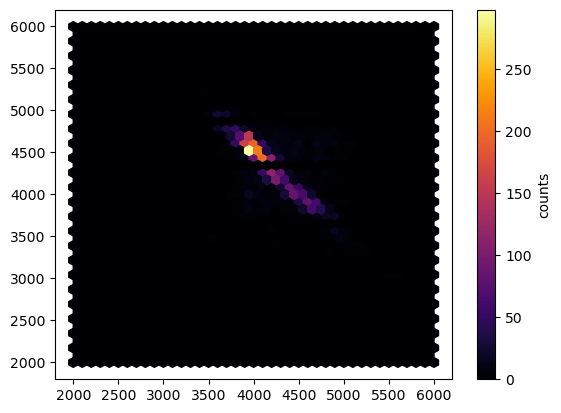

In [7]:
joint_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_357K_1p3muW_C1.txt", "/home/dominic/Downloads/Dom_Timestamps_357K_1p3muW_C2.txt")

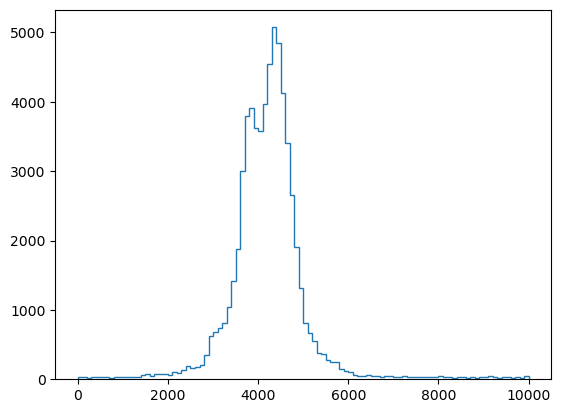

In [8]:
marginal_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_360K_1p3muW_C1.txt")

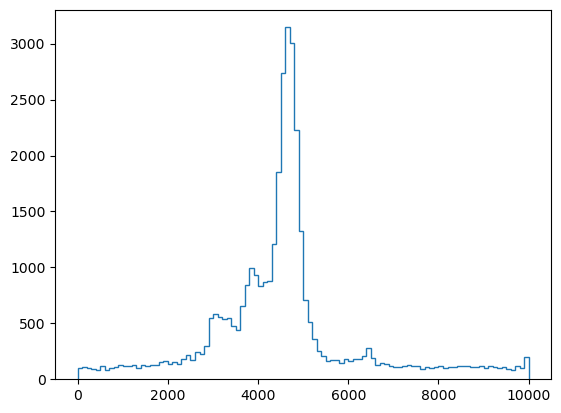

In [9]:
marginal_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_360K_1p3muW_C2.txt")

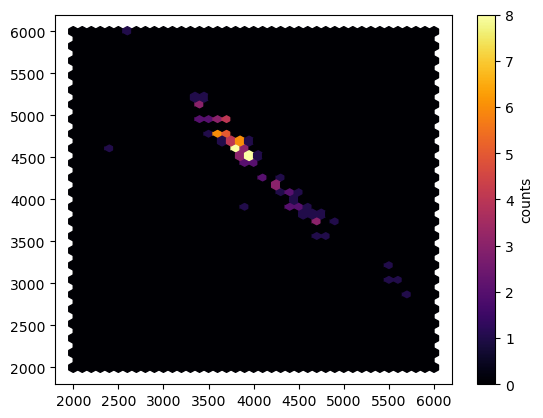

In [10]:
joint_temporal_intensity("/home/dominic/Downloads/Dom_Timestamps_360K_1p3muW_C1.txt","/home/dominic/Downloads/Dom_Timestamps_360K_1p3muW_C2.txt")